# Dopyt spotrebiteľa

## Marshallove dopytové funkcie

Správanie spotrebiteľa sme opísali úlohou na viazaný extrém, v ktorej spotrebiteľ výberom spotreby $\mathbf{x}$ maximalizuje {eq}`funkcia_uzitocnosti` vzhľadom na spotrebiteľov rozpočet {eq}`rozpocet-spotrebitel` pri nezápornosti rozhodovacích premenných {eq}`spotrebitel_nezapornost`. V ďalšom texte budeme túto úlohu nazývať aj Marshallova úloha.

(def_marshall_uloha)=

Marshallova úloha
: spotrebiteľova úloha maximilizovať užitočnosť {eq}`funkcia_uzitocnosti` vzhľadom na rozpočet {eq}`rozpocet-spotrebitel` a {eq}`spotrebitel_nezapornost`

Podmienky prvého rádu úlohy sú {eq}`r_PPR_spotrebitel1` a {eq}`r_PPR_spotrebitel2`.

Riešením úlohy maximalizácie užitočnosti alebo ekvivalentne riešením podmienok prvého rádu získame redukovaný tvar úlohy.

Marshallove dopytové funkcie
: {ref}`redukovany_tvar` {eq}`funkcia_uzitocnosti`, {eq}`rozpocet-spotrebitel` a {eq}`spotrebitel_nezapornost`.

```{math}
:label: marshall
\mathbf{x^*} = \mathbf{x}(M,\mathbf{p}).
```

Marshallove dopytové funkcie vyjadrujú spotrebiteľov dopyt po jednotlivých statkoch v závislosti od rozpočtu spotrebiteľa a cien statkov.

{ref}`komparativna_statika` ako sa mení optimálny spotrebiteľský kôš pri zmenách rozpočtu spotrebiteľa a cien statkov.

## Vplyv zmeny rozpočtu na spotrebu statkov

Ako sa zmení spotreba statkov, ak sa spotrebiteľovi zmení rozpočet, *{ref}(cp-label)*?

- Statok je **normálny**, ak sa zvyšením príjmu, *ceteris paribus*, **nezníži** jeho spotreba,

$$
\frac{\partial x_i(M,\mathbf{p})}{\partial M} \ge 0.
$$

- Statok je **podradný**, ak sa zvyšením príjmu, *ceteris paribus*, **zníži** jeho spotreba,

$$
\frac{\partial x_i(M,\mathbf{p})}{\partial M} < 0.
$$

Ak uvažujeme o normálnmych statkoch, možno ich klasifikovať podľa príjmovej elasticity ({ref}`elasticita-label`)

```{math}
:label: r_prijmova_elasticita
\varepsilon_M = \frac{\partial x_i(M,\mathbf{p})}{\partial M} \frac{M}{x_i(M,\mathbf{p})}.
```

- statok je luxusný, ak

$$
\varepsilon_M > 1,
$$

- statok je nevyhnutný (základný), ak

$$
0 < \varepsilon_M < 1.
$$
- statok je **zberateľský**, ak

$$
\varepsilon_M = 1.
$$

Spotreba zberateľských statkov sa mení rovnakým pomerom ako sa mení spotrebiteľov rozpočet, *ceteris paribus*.

Statky s jednotkovou príjmovou elasticitou sa v slovenskej mikroekonomickej literatúre často označujú ako zberateľské statky.

Na {numref}`graf_prijmovy_spotrebitel` sú oba statky normálne a zberateľské.


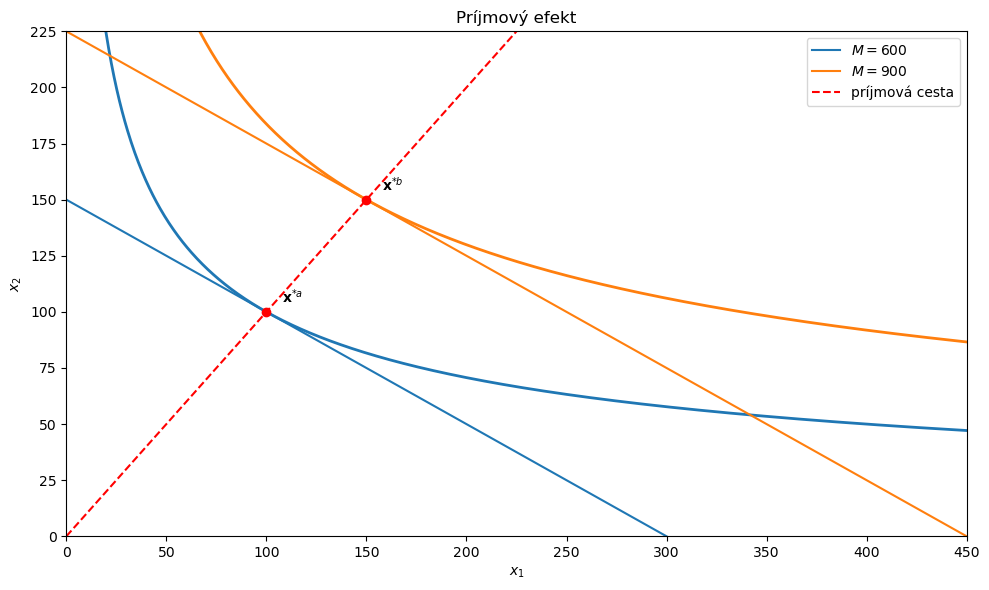

In [4]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10, 6)

# --------------------------------------------------
# funkcie
# --------------------------------------------------

def x_opt(alpha, beta, M, p):
    return alpha/(alpha + beta) * M/p

def uzitocnost(x1, x2, alpha, beta):
    return x1**alpha * x2**beta

def rozpocet(x1, M, p1, p2):
    return M/p2 - p1/p2 * x1

def indiferencna_krivka(x1, u, alpha, beta):
    return (u / x1**alpha)**(1/beta)

# --------------------------------------------------
# parametre
# --------------------------------------------------

alpha = 1/3
beta = 2/3

p1 = 2
p2 = 4

M_values = [600, 900]

x1 = np.linspace(1e-6, 450, 1000)

# --------------------------------------------------
# graf
# --------------------------------------------------

fig, ax = plt.subplots()

opt_x = []
opt_y = []

for i, M in enumerate(M_values):

    # optimum
    x1_opt = x_opt(alpha, beta, M, p1)
    x2_opt = x_opt(beta, alpha, M, p2)

    u_opt = uzitocnost(
        x1_opt,
        x2_opt,
        alpha,
        beta
    )

    # rozpočtová priamka
    ax.plot(
        x1,
        rozpocet(x1, M, p1, p2),
        label=rf'$M={M}$'
    )

    # indiferenčná krivka
    ax.plot(
        x1,
        indiferencna_krivka(
            x1,
            u_opt,
            alpha,
            beta
        ),
        color='C' + str(i),
        lw=2
    )

    # optimum
    ax.scatter(
        x1_opt,
        x2_opt,
        color='red',
        zorder=5
    )

    label = 'a' if i == 0 else 'b'

    ax.text(
        x1_opt + 8,
        x2_opt + 4,
        rf'$\mathbf{{x}}^{{*{label}}}$'
    )

    opt_x.append(x1_opt)
    opt_y.append(x2_opt)

# --------------------------------------------------
# príjmová cesta
# --------------------------------------------------

# príjmová cesta

xp = np.linspace(0, 450, 200)

ax.plot(
    xp,
    xp,
    'r--',
    lw=1.5,
    label='príjmová cesta'
)

# --------------------------------------------------
# vzhľad
# --------------------------------------------------

ax.set(
    xlabel=r'$x_1$',
    ylabel=r'$x_2$',
    xlim=(0, 450),
    ylim=(0, 225)
)

ax.legend()

ax.set_title('Príjmový efekt')

plt.tight_layout()
plt.show()

```{figure} images/porovn/graf_prijmovy_spotrebitel.png
:name: graf_prijmovy_spotrebitel

Vplyv zvýšenia rozpočtu na správanie spotrebiteľa 
```

Klasifikácia statkov podľa reakcie spotreby na zmenu rozpočtu

```{Table} Klasifikácia statkov podľa reakcie spotreby na zmenu rozpočtu
:name: tab_prijmovy_efekt
| Typ statku | Podmienka |
|------------|------------|
| normálny | $\displaystyle \frac{\partial x_i(M,\mathbf{p})}{\partial M}\ge 0$ |
| podradný | $\displaystyle \frac{\partial x_i(M,\mathbf{p})}{\partial M}<0$ |
| luxusný | $\displaystyle \varepsilon_M>1$ |
| zberateľský | $\displaystyle \varepsilon_M=1$ |
| nevyhnutný (základný) | $\displaystyle 0<\varepsilon_M<1$ |
```

## Vplyv zmeny cien na spotrebu statkov

Ako sa zmení spotrebiteľova spotreba statkov, ak sa zmení cena niektorého zo statkov, {ref}`cp-label`?

Rozlišujme vplyv zmeny vlastnej ceny a krížovej ceny.

Vplyv zmeny vlastnej ceny
: Zaujíma nás, ako sa zmení spotrebiteľovi spotreba statku, ak sa *jeho* cena zmení, *ceteris paribus*.

Vplyv zmeny krížovej ceny
: Zaujíma nás, ako sa zmení spotrebiteľovi spotreba statku, ak sa zmení cena *iného* statku, *ceteris paribus*.

- Statok je **štandardný**, ak sa zvyšením jeho ceny, *ceteris paribus*, jeho spotreba **nezvýši**,

$$
\frac{\partial x_i(M,\mathbf{p})}{\partial p_i} \le 0.
$$

- Statok je **Giffenov**, ak sa zvyšením jeho ceny, *ceteris paribus*, jeho spotreba **zvýši**,

$$
\frac{\partial x_i(M,\mathbf{p})}{\partial p_i} > 0.
$$

- Dva statky sú **substitúty**, ak sa zvýšením ceny jedného, *ceteris paribus*, **zvýši** spotreba druhého (cukor, med),

$$
\frac{\partial x_i(M,\mathbf{p})}{\partial p_j} > 0 \quad i \ne j.
$$

- Dva statky sú **komplementárne**, ak sa zvýšením ceny jedného, *ceteris paribus*, **zníži** spotreba druhého (benzín, automobil),


$$
\frac{\partial x_i(M,\mathbf{p})}{\partial p_j} < 0 \quad i \ne j.
$$

Ak uvažujeme o štandardných statkoch, možno ich klasifikovať podľa cenovej elasticity ({ref}`elasticita-label`)

```{math}
:label: r_cenova_elasticita
\varepsilon_p = \frac{\partial x_i(M,\mathbf{p})}{\partial p_i} \frac{p_i}{x_i(M,\mathbf{p})}.
```

- statok je elastický, ak

$$
|\varepsilon_p| > 1,
$$

- statok je neelastický, ak

$$
|\varepsilon_p| < 1.
$$
- statok je jednotkovo-elastický, ak

$$
|\varepsilon_p| = 1.
$$

Na {numref}`graf_standardny_spotrebitel` sú oba statky štandardné. Krížové cenové efekty sú nulové, preto statky nie sú ani substitúty, ani komplementy.

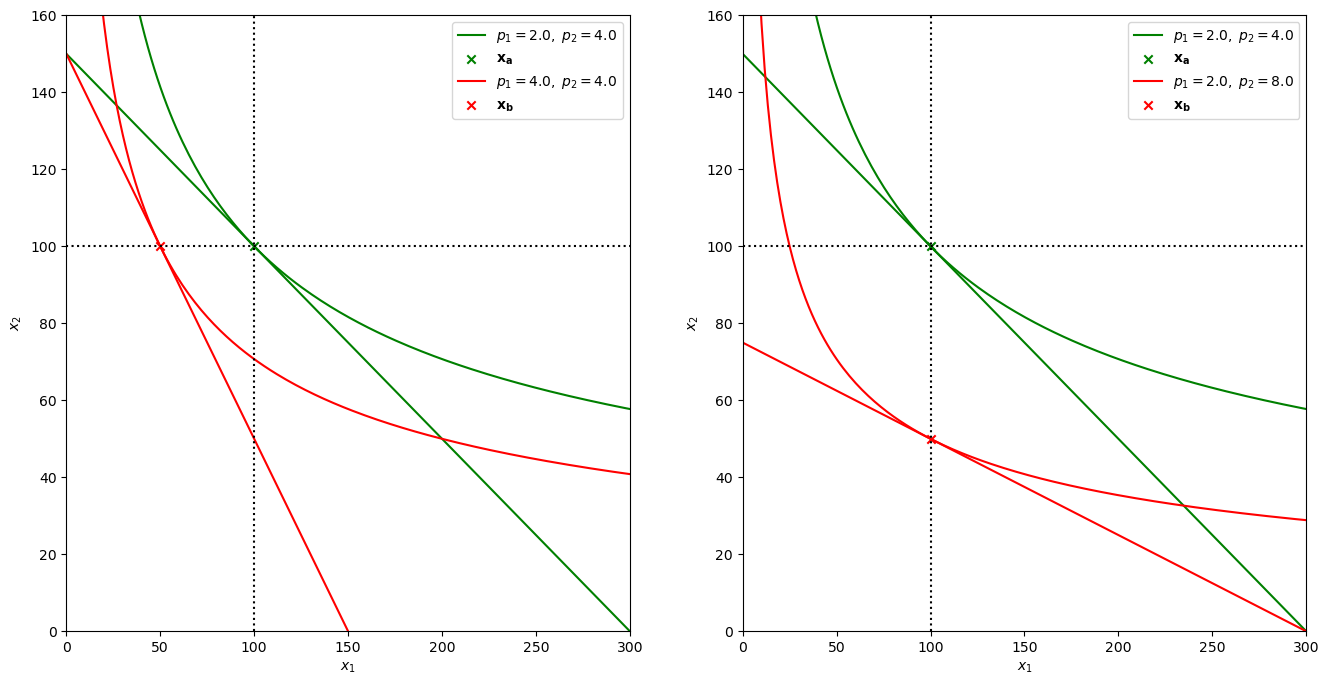

In [5]:
def zobraz(ax, M, p1ky, p2ky):
    
    for (M, p1, p2, f, o) in zip(M, p1ky, p2ky, farby, ozn):
        r = rozpocet(x1,M,p1,p2) # rozpočet
        ax.plot(x1,r, label=rf"$p_1 = {p1},\; p_2 = {p2}$", color = f)
        xx1 = x_opt(𝛼, 𝛽, M, p1)
        xx2 = x_opt(𝛽, 𝛼, M, p2)
        h = uzitocnost(xx1,xx2,𝛼, 𝛽)
        ind = h**(1/𝛽) / x1**(𝛼/𝛽) # indiferenčná krivka
        ax.plot(x1,ind, color = f)
        ax.scatter(xx1,xx2,marker='x', color = f, label = o)
        
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Parameters
𝛼, 𝛽 = 1/3, 2/3

set1 = ([600.,600.], [2.,4.], [4.,4.],['g','r'], ['$\mathbf{x_a}$','$\mathbf{x_b}$'])
set2 = ([600.,600.], [2.,2.], [4.,8.],['g','r'], ['$\mathbf{x_a}$','$\mathbf{x_b}$'])

x1 = np.linspace(1e-12,500,300)

for (ax, exo) in zip(axes, (set1, set2)):
    M, p1ky, p2ky, farby, ozn = exo
    zobraz(ax, M, p1ky, p2ky)
    ax.plot([0,300],[100,100], ':', color = 'black') # čiary cez pôvodný kôš, horizontálna
    ax.plot([100,100],[0,160], ':', color = 'black') # vertikálna
    ax.set_ylim(0,160)
    ax.set_xlim(0,300)
    ax.legend(loc='upper right', frameon=True)
    
plt.show()

```{figure} images/porovn/graf_standardny_spotrebitel.png
:name: graf_standardny_spotrebitel

Vplyv zvýšenia ceny na správanie spotrebiteľa 
```

```{Table} Klasifikácia statkov podľa reakcie spotreby na zmenu ceny
:name: tab_zmena_ceny
| Typ statku | Podmienka |
|------------|------------|
| štandardný | $\displaystyle \frac{\partial x_i(M,\mathbf{p})}{\partial p_i}\le 0$ |
| Giffenov | $\displaystyle \frac{\partial x_i(M,\mathbf{p})}{\partial p_i}>0$ |
| substitút | $\displaystyle \frac{\partial x_i(M,\mathbf{p})}{\partial p_j}>0,\quad i\neq j$ |
| komplement | $\displaystyle \frac{\partial x_i(M,\mathbf{p})}{\partial p_j}<0,\quad i\neq j$ |
| nezávislý statok | $\displaystyle \frac{\partial x_i(M,\mathbf{p})}{\partial p_j}=0,\quad i\neq j$ |
```

Marshallove dopytové funkcie opisujú optimálne rozhodnutie spotrebiteľa pri danom rozpočte.

Pri zmene ceny statku sa však súčasne menia:

- relatívne ceny statkov,
- kúpna sila spotrebiteľa.

Z celkovej zmeny spotreby preto nie je možné priamo určiť, aká časť zmeny je spôsobená zmenou relatívnych cien a aká časť zmenou kúpnej sily spotrebiteľa.

Ako oddeliť tieto dva vplyvy?

V {ref}`priklad_marshall` odvodíme Marshallove dopytové funkcie dvoch statkov {eq}`Marshall_CD` spotrebiteľa s preferenciami opísanými Cobbovou-Douglasovou funkciou užitočnosti s konštatntnými výnosmi z rozsahu {eq}`uzitocnost_CD_KVR`.

S danými preferenciami, dva statky ({ref}`priklad_spotrebitel_ks`)

- sú normálne a zberateľské; príjmové elasticity spotreby sa rovnajú 1,
- sú štandardné a jednotkovo-elastické,
- nie sú ani substitúty ani komplementy.

## Hicksove dopytové funkcie

Doteraz sme správanie spotrebiteľa opisovali ako úlohu maximalizácie užitočnosti {eq}`funkcia_uzitocnosti` pri danom rozpočte {eq}`rozpocet-spotrebitel`.

Rovnaké rozhodovanie možno opísať aj opačne.

Predpokladajme, že spotrebiteľ požaduje dosiahnuť úroveň užitočnosti $\bar u$. Ktorý spotrebiteľský kôš mu umožní dosiahnuť túto úroveň užitočnosti pri minimálnych výdavkoch?

Takúto úlohu spotrebiteľa zapíšeme v tvare
 
```{math}
:label: hicks_ul
M_{min} = \min_{\mathbf{x}}
\quad
\mathbf{p}^\top\mathbf{x},
```

vzhľadom na ohraničenie

```{math}
:label: hicks_obm
u(\mathbf{x}) - \bar u \ge 0,
```

a nezápornosť rozhodovacích premenných

```{math}
:label: hicks_nezap
\mathbf{x} \ge 0.
```

(def_hicks_uloha)=

Hicksova úloha
: spotrebiteľova úloha minimalizovať výdavky {eq}`hicks_ul` vzhľadom na užitočnosť {eq}`hicks_obm` a {eq}`spotrebitel_nezapornost`

Na {numref}`graf_hicks_ul` je znázornená úloha minimalizácie výdavkov spotrebiteľa.

Zelená krivka predstavuje hranicu prípustných riešení, teda všetky spotrebiteľské koše poskytujúce požadovanú úroveň užitočnosti
$\bar u$.

Modrá priamka predstavuje vrstevnicu výdavkovej (rozpočtovej) funkcie. Každý bod na nej vyžaduje rovnaké výdavky.

Optimálny spotrebiteľský kôš $\mathbf{h}^*$ vzniká v bode dotyku hranice prípustných riešení a vrstevnice výdavkovej funkcie.

V tomto bode sú minimálne výdavky potrebné na dosiahnutie úrovne užitočnosti $\bar u$.

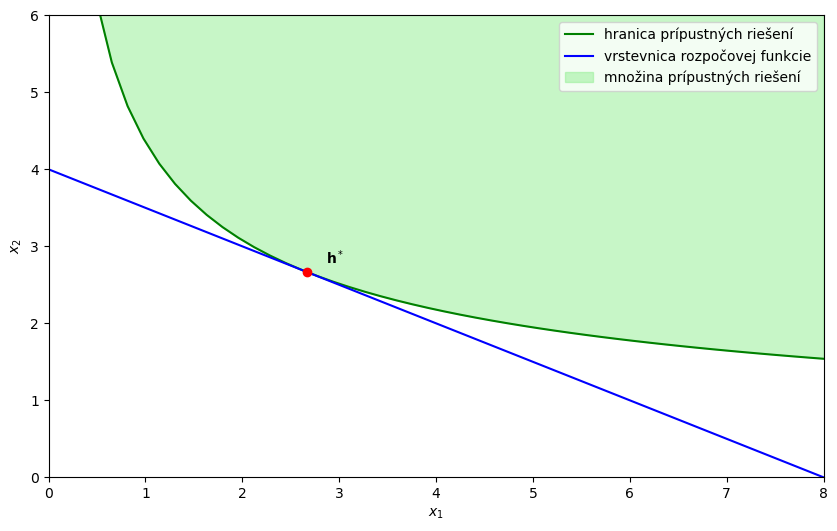

In [15]:
def ik(x1, u):
    return u**(3/2) / x1**(1/2)

def ir(x1, M, p1, p2):
    return M / p2 - p1 / p2 * x1

M = 40
p_1 = 5
p_2 = 10

x1opt = M/3/p_1
x2opt = 2*M/3/p_2
x1opt, x2opt
uopt = x1opt**(1/3) * x2opt**(2/3)

x_1 = np.linspace(1e-12,8)

iuzit = ik(x_1,u=uopt)
irozp = ir(x_1,M,p_1,p_2)

fig, ax = plt.subplots()

ax.plot(x_1,iuzit,color='green',
    label='hranica prípustných riešení')
ax.plot(x_1,irozp,color='b',
    label='vrstevnica rozpočovej funkcie')
ax.set_xlim(0,8)
ax.set_ylim(0,6)

ax.fill_between(x_1,iuzit,y2=6, color = 'lightgreen', alpha=0.5,
               label = 'množina prípustných riešení')

ax.scatter(
    x1opt,
    x2opt,
    color='r',
    zorder=5
)

ax.text(
    x1opt + 0.2,
    x2opt + 0.1,
    r'$\mathbf{h}^*$'
)

ax.set(
    xlabel=r'$x_1$',
    ylabel=r'$x_2$',
    xlim=(0,8),
    ylim=(0,6)
)

ax.legend()

plt.show()

```{figure} images/porovn/graf_hicks_ul.png
:name: graf_hicks_ul

Hicksova úloha minimalizácie užitočnosti vzhľadom na pevný rozpočet 
```

Ak optimálny spotrebiteľský kôš leží vo vnútri definičného oboru, potom platia podmienky prvého rádu.

1. Optimálny spotrebiteľský kôš leží na hranici prípustných riešení

```{math}
:label: r_hicks_ul_u
u(\mathbf{x})
=
\bar u.
```

2. Hraničná miera spotrebiteľskej substitúcie sa rovná pomeru cien statkov

```{math}
:label: r_hicks_ul
MRS(x_1,x_2)
=
\frac{p_1}{p_2}.
```

Podmienka prvého rádu {eq}`r_hicks_ul` sa zhoduje s podmienkou Marshallovej úlohy {eq}`marshall`. Rozdiel dvoch úloh spočíva v interpretácii.

V Marshallovej úlohe ({ref}`def_marshall_uloha`) hľadáme najvyššiu dosiahnuteľnú úroveň užitočnosti pri danom rozpočte.

V Hicksovej úlohe ({ref}`def_hicks_uloha`) hľadáme najnižšie výdavky potrebné na dosiahnutie danej úrovne užitočnosti.

Riešením úlohy minimalizácie výdavkov získame redukovaný tvar úlohy. 

Hicksove dopytové funkcie 
: {ref}`redukovany_tvar` úlohy {eq}`hicks_ul`, {eq}`hicks_obm` a {eq}`hicks_nezap`.

```{math}
:label: hicks
\mathbf{x^*}=\mathbf{h}(\bar u,\mathbf p).
```

Hicksove dopytové funkcie vyjadrujú spotrebiteľov dopyt po jednotlivých statkoch v závislosti od jeho požadovaného blahobytu a cien statkov.

Pre odvodenie Hicksových dopytových funkcií s preferenciami {eq}`uzitocnost_CD_KVR` pozri {ref}`priklad_spotrebitel_hicks`.

## Výdavková funkcia 

Dosadením Hicksových dopytových funkcií do výdavkov spotrebiteľa získame výdavkovú funkciu. 

Výdavková funkcia 
: Optimálna hodnota účelovej funkcie {eq}`hicks_ul`. 

```{math} 
:label: vydavkova_funkcia 
e(\bar u,\mathbf p) = \mathbf p^\top \mathbf h(\bar u,\mathbf p).
```

Výdavková funkcia vyjadruje minimálne výdavky potrebné na dosiahnutie úrovne užitočnosti $\bar u$ pri daných cenách statkov.

## Vzťah medzi Marshallovými a Hicksovými dopytovými funkciami

Marshallove dopytové funkcie {eq}`marshall` vyjadrujú optimálny spotrebiteľský kôš pri danom rozpočte a cenách statkov.

Hicksove dopytové funkcie {eq}`hicks` vyjadrujú najlacnejší spotrebiteľský kôš, ktorý umožňuje dosiahnuť úroveň užitočnosti $\bar u$ pri daných cenách statkov.

V úlohe {eq}`funkcia_uzitocnosti`, {eq}`rozpocet-spotrebitel` a {eq}`spotrebitel_nezapornost` (Marshall) je daný rozpočet a výsledkom je dosiahnutá úroveň užitočnosti. V úlohe {eq}`hicks_ul`, {eq}`hicks_obm` a {eq}`hicks_nezap` (Hicks) je daná úroveň užitočnosti a výsledkom sú minimálne výdavky potrebné na jej dosiahnutie.

Dosadením Marshallových dopytových funkcií pri rozpočte $M$ do funkcie užitočnosti získame úroveň užitočnosti

$$
\bar u
=
u(\mathbf{x}(M,\mathbf p)).
$$

Potom Hicksove dopytové funkcie pri tejto úrovni užitočnosti vedú k rovnakému optimálnemu spotrebiteľskému košu

$$
\mathbf{h}(\bar u,\mathbf p)
=
\mathbf{x}(M,\mathbf p).
$$

Naopak, ak pri úrovni užitočnosti $\bar u$ označíme minimálne výdavky

$$
M
=
e(\bar u,\mathbf p),
$$

potom Marshallove dopytové funkcie vedú k rovnakému optimálnemu spotrebiteľskému košu

$$
\mathbf{x}(e(\bar u,\mathbf p),\mathbf p)
=
\mathbf{h}(\bar u,\mathbf p).
$$

Marshallove a Hicksove dopytové funkcie preto opisujú rovnaké správanie spotrebiteľa z dvoch rôznych pohľadov.

Marshallove dopytové funkcie sú vhodné na analýzu správania spotrebiteľa pri danom rozpočte. Hicksove dopytové funkcie umožňujú analyzovať správanie spotrebiteľa pri nezmenenej úrovni užitočnosti, čo je základom rozkladu vplyvu zmeny ceny na substitučný a príjmový efekt.

## Rozklad vplyvu zmeny ceny

Uvažujme ďalej o dvoch štandardných a normálnych statkoch.

Ak sa cena jedného statku zvýši, jeho spotreba klesne, pretože ide o štandardný statok. Ako sa však zmení spotreba druhého statku?

Vieme, že ak sa spotreba druhého statku zvýši, oba statky sú substitúty. Ak sa spotreba druhého statku zníži, oba statky sú
komplementy.

Celkový vplyv zmeny ceny možno rozdeliť na príjmový a substitučný efekt.

Ak sa zvýši cena jedného zo statkov, spotrebiteľovi klesne reálny príjem. Peňažný rozpočet spotrebiteľa sa síce nezmení, ale za rovnaký rozpočet si už nemôže dovoliť niektoré spotrebiteľské koše, ktoré si mohol dovoliť pred zvýšením ceny.

Pri normálnych statkoch vedie pokles reálneho príjmu k poklesu spotreby oboch statkov. Tento vplyv nazývame príjmový efekt.

Zároveň sa zmení pomer cien statkov. Statok, ktorého cena sa zvýšila, sa stáva relatívne drahším a druhý statok relatívne lacnejším.

Substitučným efektom spotrebiteľ reaguje na zmenu relatívnych cien tak, že znižuje spotrebu relatívne drahšieho statku a zvyšuje
spotrebu relatívne lacnejšieho statku.

Z uvedeného vyplýva, že zvýšenie ceny jedného zo statkov spôsobí:

- príjmovým efektom pokles spotreby oboch statkov,
- substitučným efektom pokles spotreby statku, ktorého cena sa zvýšila,
  a rast spotreby druhého statku.

Celkový efekt je súčtom príjmového a substitučného efektu.

Spotreba statku, ktorého cena sa zvýšila, klesá príjmovým aj substitučným efektom. Celkovým efektom zvýšenia ceny je preto pokles spotreby tohto statku.

Pri druhom statku pôsobia oba efekty opačným smerom. Príjmový efekt znižuje jeho spotrebu, zatiaľ čo substitučný efekt ju zvyšuje.

Preto:

- ak sa spotreba druhého statku zvýši, substitučný efekt prevláda nad príjmovým efektom a oba statky sú substitúty,
- ak sa spotreba druhého statku zníži, príjmový efekt prevláda nad substitučným efektom a oba statky sú komplementy,
- ak sa spotreba druhého statku nezmení, príjmový a substitučný efekt sa navzájom vykompenzujú.

## Hicksova interpretácia príjmového a substitučného efektu

V predchádzajúcej časti sme ukázali, že zmena ceny statku ovplyvňuje spotrebu prostredníctvom príjmového a substitučného efektu.

Pri pozorovaní zmeny Marshallových dopytových funkcií však vidíme iba celkový efekt zmeny ceny. Samotné Marshallove dopytové funkcie neumožňujú určiť, aká časť zmeny spotreby bola spôsobená zmenou relatívnych cien a aká časť zmenou reálneho príjmu spotrebiteľa.

Na oddelenie oboch efektov využijeme Hicksove dopytové funkcie.

Hicksova interpretácia príjmového a substitučného efektu
: Rozklad celkového efektu zmeny ceny na substitučný a príjmový efekt pri nezmenenej úrovni užitočnosti spotrebiteľa.

Predpokladajme, že sa zvýši cena prvého statku $p_1$.

Pôvodný optimálny spotrebiteľský kôš je $\mathbf{x_a}$.

Po zvýšení ceny sa zmení sklon hranice spotrebiteľských možností $p_1/p_2$ a nový optimálny spotrebiteľský kôš je $\mathbf{x_b}$.

Táto zmena predstavuje celkový efekt zmeny ceny.

Aby sme oddelili substitučný efekt od príjmového efektu, kompenzujeme spotrebiteľovi zvýšenie ceny tak, aby zostal na pôvodnej
úrovni užitočnosti. Napríklad mu vláda poskytne dodatočný príjem kompenzujúci zvýšenie ceny. Tým sa podľa Hicksovej koncepcie eliminuje príjmový efekt.

Pri tejto kompenzácii spotrebiteľ zvolí nový optimálny spotrebiteľský kôš $\mathbf{x_s}$.

Presun z bodu $\mathbf{x_a}$ do bodu $\mathbf{x_s}$ predstavuje substitučný efekt.

Presun z bodu $\mathbf{x_s}$ do bodu $\mathbf{x_b}$ predstavuje príjmový efekt.

Na {numref}`graf_hicks` je v hornom paneli zobrazený rozklad celkového efektu zmeny ceny prvého statku na substitučný a príjmový efekt.

V dolnom paneli je zobrazený rozklad celkového efektu zmeny ceny druhého statku.

Pôvodný optimálny spotrebiteľský kôš $\mathbf{x_a}$ je zobrazený zelenou farbou.

Nový optimálny spotrebiteľský kôš $\mathbf{x_b}$ je zobrazený červenou farbou.

Elimináciu príjmového efektu kompenzáciou zvýšenia ceny predstavuje posun červenej hranice spotrebiteľských možností do modrej. Modrá hranica spotrebiteľských možností je rovnobežná s červenou hranicou, pretože obe zodpovedajú rovnakému pomeru cien $p_1/p_2$.

Hranica spotrebiteľských možností sa posúva dovtedy, kým sa nedotkne pôvodnej indiferenčnej krivky, ktorá predstavuje pôvodnú úroveň užitočnosti spotrebiteľa.

Bod dotyku $\mathbf{x_s}$ je zobrazený modrou farbou. Presun z bodu $\mathbf{x_a}$ do bodu $\mathbf{x_s}$ predstavuje substitučný efekt. Presun z bodu $\mathbf{x_s}$ do bodu $\mathbf{x_b}$ predstavuje príjmový efekt.

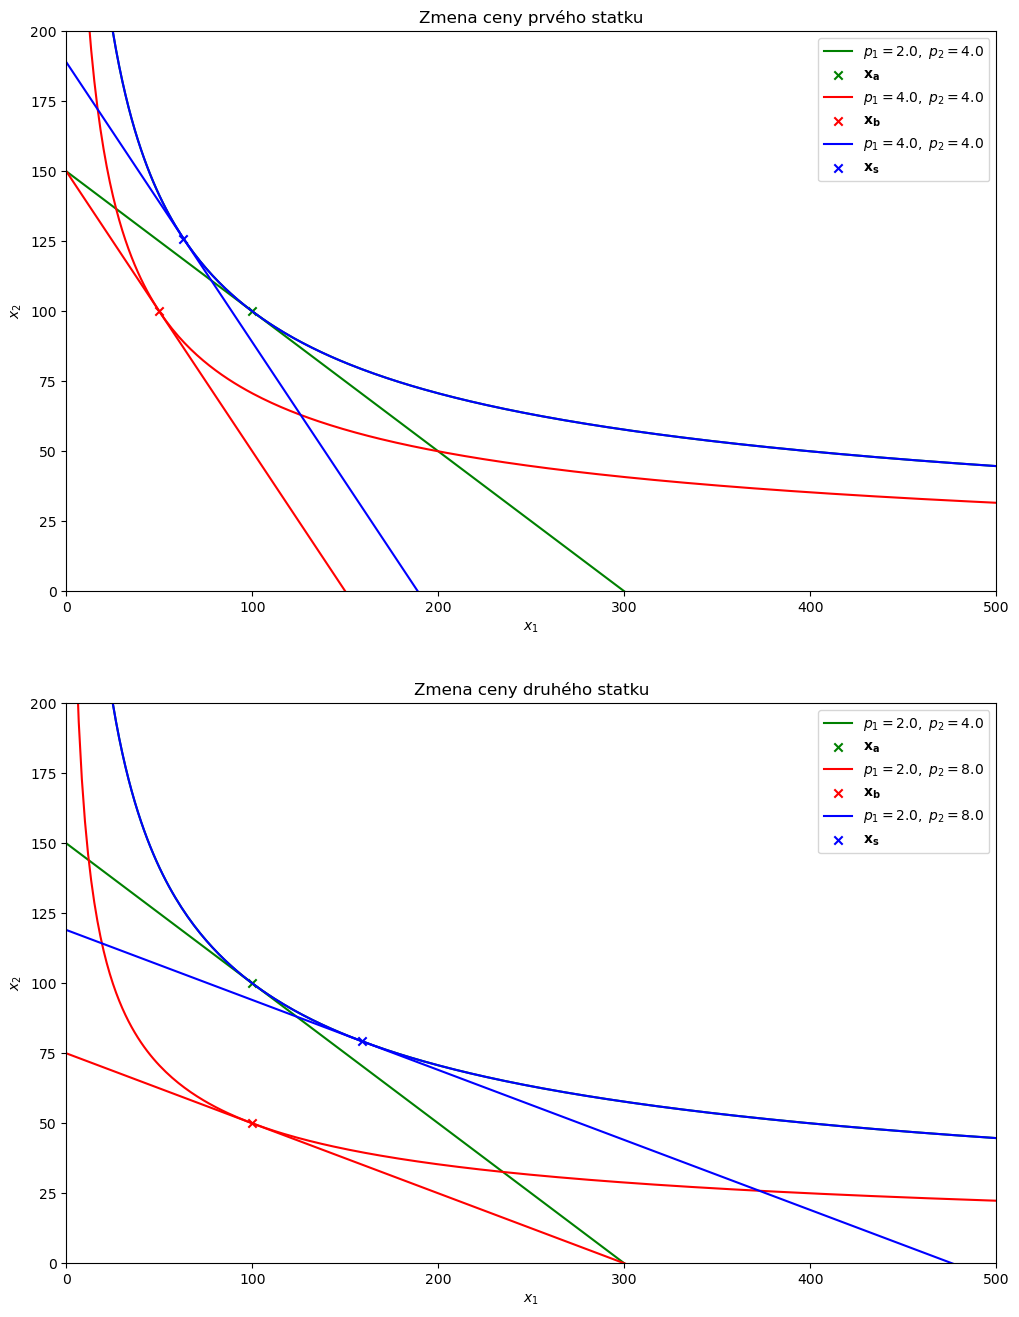

In [10]:
x1a = x_opt(α, β, 600, 2)
x2a = x_opt(β, α, 600, 4)

u0 = uzitocnost(x1a, x2a, α, β)

Mh1 = (
    u0
    * set1[1][1]**α
    * set1[2][1]**β
    / (α**α * β**β)
)

Mh2 = (
    u0
    * set2[1][1]**α
    * set2[2][1]**β
    / (α**α * β**β)
)

set1h = ([600.,600.,Mh1], [2.,4.,4.], [4.,4.,4.],['g','r','b'], ['$\mathbf{x_a}$','$\mathbf{x_b}$','$\mathbf{x_s}$'])
set2h = ([600.,600.,Mh2], [2.,2.,2.], [4.,8.,8.],['g','r','b'], ['$\mathbf{x_a}$','$\mathbf{x_b}$','$\mathbf{x_s}$'])

fig, axes = plt.subplots(2, 1, figsize=(12, 16))

x1 = np.linspace(1e-12,500,300)

for (ax, exo) in zip(axes, (set1h, set2h)):
    Mka, p1ky, p2ky, farby, ozn = exo
    zobraz(ax, Mka, p1ky, p2ky)
    ax.set_xlim(0,500)
    ax.set_ylim(0,200)
    ax.legend(loc='upper right', frameon=True)

axes[0].set_title("Zmena ceny prvého statku")
axes[1].set_title("Zmena ceny druhého statku")

plt.show()

```{figure} images/porovn/graf_hicks.png
:name: graf_hicks

Rozklad celkového efektu zmeny ceny na substitučný a príjmový podľa Hicksovej koncepcie
```

## Hicksov rozklad cenového efektu

Označme Marshallov dopyt po statku $i$ ako $x_i(M,\mathbf p)$ a Hicksov dopyt $h_i(\bar u,\mathbf p)$.

Pri zmene ceny statku $p_j$ možno celkový efekt rozdeliť na:

- substitučný efekt,
- príjmový efekt.

Substitučný efekt zachytáva zmenu Hicksovho dopytu

$$
se = \frac{\partial h_i(\bar u,\mathbf p)}{\partial p_j}.
$$

Celkový efekt zachytáva zmenu Marshallovho dopytu

$$
ce = \frac{\partial x_i(M,\mathbf p)}{\partial p_j}.
$$

Príjmový efekt vzniká preto, že zmena ceny mení reálny rozpočet
spotrebiteľa.

Ak sa zmení cena statku $j$, rozpočet potrebný na kúpu pôvodného
spotrebiteľského koša sa zmení o

$$
dM=x_j\,dp_j.
$$

Vplyv tejto zmeny rozpočtu na spotrebu statku $i$ je

$$
pe
=
\frac{\partial x_i(M,\mathbf p)}
{\partial M}
\frac{dM}{dp_j}.
$$

Keďže

$$
\frac{dM}{dp_j}
=
x_j,
$$

dostávame

$$
pe
=
x_j
\frac{\partial x_i(M,\mathbf p)}
{\partial M}.
$$

## Slutského rovnica

Celkový efekt zmeny ceny sa rovná súčtu substitučného a príjmového efektu.

```{math}
:label: slutsky
\frac{\partial x_i(M,\mathbf p)}{\partial p_j}
=
\frac{\partial h_i(\bar u,\mathbf p)}{\partial p_j}
-
x_j(M,\mathbf p)
\frac{\partial x_i(M,\mathbf p)}{\partial M}.
```

Ak $i=j$, rovnica {eq}`slutsky` opisuje rozklad vlastného cenového efektu.

Ak $i\neq j$, rovnica {eq}`slutsky` opisuje rozklad krížového cenového efektu.

$$ \frac{\partial x_i(M,\mathbf p)}{\partial p_j}
=
\frac{\partial h_i(\bar u,\mathbf p)}{\partial p_j}
-
x_j(M,\mathbf p)
\frac{\partial x_i(M,\mathbf p)}{\partial M}. $$

Ľavá strana {eq}`slutsky` predstavuje celkový efekt zmeny ceny. 

Prvý člen na pravej strane {eq}`slutsky` predstavuje substitučný efekt. 

Druhý člen na pravej strane {eq}`slutsky` predstavuje príjmový efekt.

Pri zvýšení ceny statku sa spotrebiteľ snaží nahradiť relatívne
drahší statok relatívne lacnejšími statkami. Tento vplyv vyjadruje
substitučný efekt.

Súčasne sa znižuje reálna hodnota jeho rozpočtu. Tento vplyv
vyjadruje príjmový efekt.

Hicksova koncepcia poskytuje ekonomickú interpretáciu substitučného efektu. Slutského rovnica umožňuje substitučný efekt vypočítať priamo z Marshallových dopytových funkcií bez riešenia Hicksovho problému.

## Slutského rozklad celkového efektu na príjmový a substitučný

Alternatívou Hicksovej kompenzácie je Slutského kompenzácia, ktorá zachováva schopnosť kúpiť pôvodný optimálny spotrebiteľský kôš.

Na {numref}`graf_slutsky` to znamená kompenzáciu rozpočtu až do bodu, v ktorom hranica spotrebiteľských možností prechádza pôvodným optimálnym spotrebiteľským košom.

Slutského kompenzácia zachováva pri eliminácii príjmového efektu spotrebiteľovu kúpnu silu spotrebiteľa, zatiaľ čo Hicksova kompenzácia zachováva jeho úroveň užitočnosti.

V ďalšom texte budeme používať predovšetkým Hicksovu koncepciu.

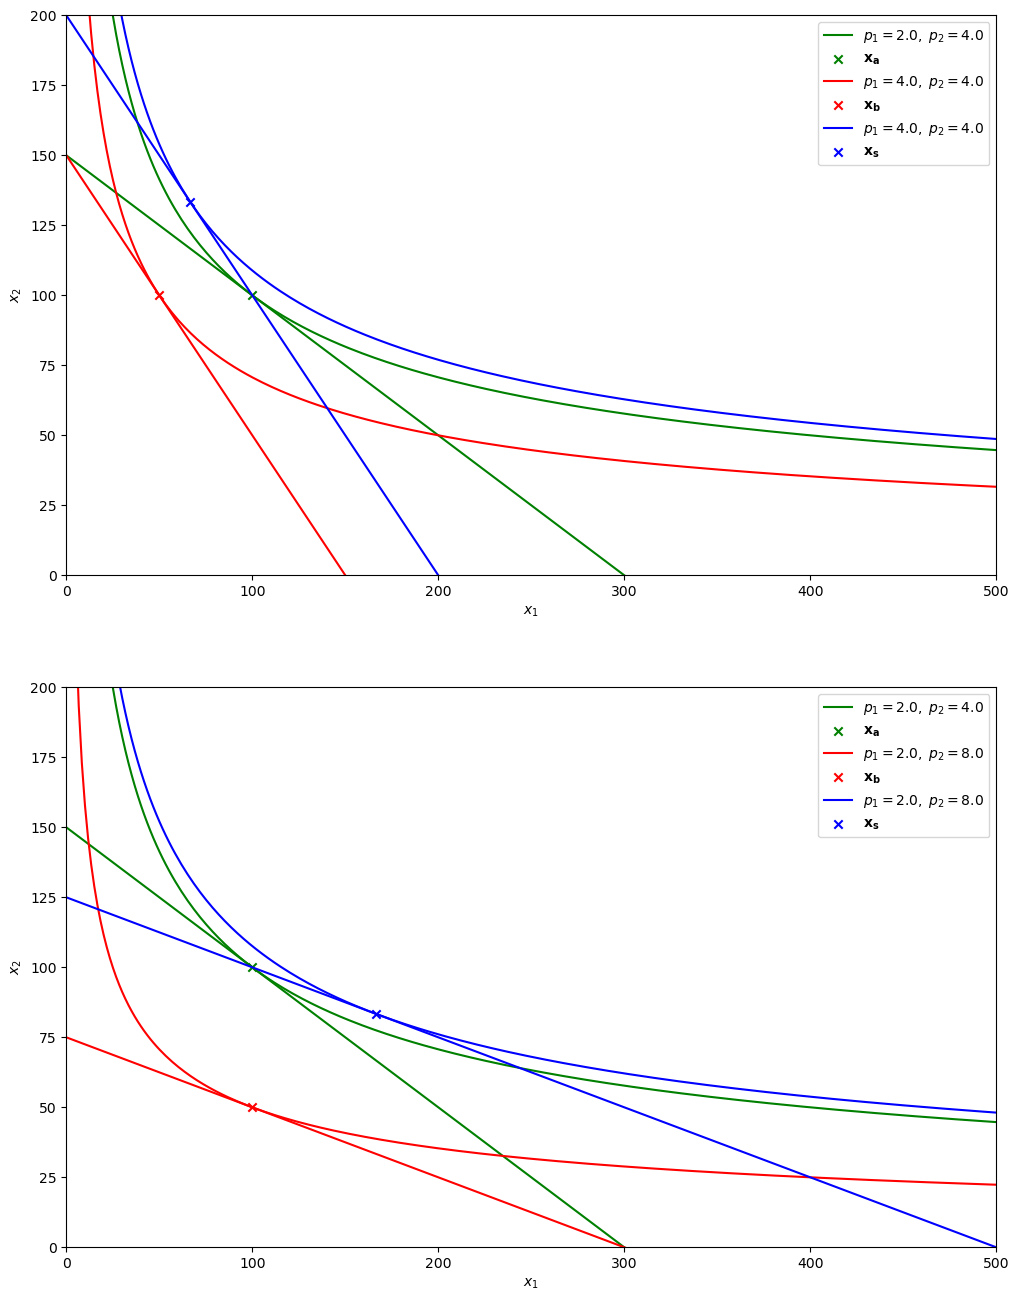

In [11]:
x1a = x_opt(𝛼, 𝛽, set1[0][0], set1[1][0])
x2a = x_opt(𝛽, 𝛼, set1[0][0], set1[2][0])

Ms1 = x1a*set1[1][1] + x2a*set1[2][1]
Ms2 = x1a*set2[1][1] + x2a*set2[2][1]

set1s = ([600.,600.,Ms1], [2.,4.,4.], [4.,4.,4.],['g','r','b'], ['$\mathbf{x_a}$','$\mathbf{x_b}$','$\mathbf{x_s}$'])
set2s = ([600.,600.,Ms2], [2.,2.,2.], [4.,8.,8.],['g','r','b'], ['$\mathbf{x_a}$','$\mathbf{x_b}$','$\mathbf{x_s}$'])

fig, axes = plt.subplots(2, 1, figsize=(12, 16))

x1 = np.linspace(1e-12,500,300)

for (ax, exo) in zip(axes, (set1s, set2s)):
    Mka, p1ky, p2ky, farby, ozn = exo
    zobraz(ax, Mka, p1ky, p2ky)
    ax.set_xlim(0,500)
    ax.set_ylim(0,200)
    ax.legend(loc='upper right', frameon=True)

plt.show()

```{figure} images/porovn/graf_slutsky.png
:name: graf_slutsky

Rozklad celkového efektu zmeny ceny na substitučný a príjmový podľa Slutského koncepcie
```

## Riešené príklady

Pri práci s Pythonom využijeme knižnice:

In [92]:
from sympy import symbols, diff, solve, simplify, sqrt

(priklad_marshall)=

### Príklad: Marshallove dopytové funkcie

Spotrebiteľove preferencie charakterizuje funkcia užitočnosti v tvare: 

```{math}
:name: uzitocnost_CD_KVR
u(x_1,x_2) = x_1^{\alpha}x_2^{1-\alpha}.
```

Odvoďte Marshallove dopytové funkcie.

#### Riešenie

Podmienky prvého rádu {eq}`r_PPR_spotrebitel1` a {eq}`r_PPR_spotrebitel2` zapíšeme v tvare

$$
x_1 p_1 + x_2 p_2 = M
$$

a

$$
\frac {\alpha x_1^{\alpha-1}x_2^{1-\alpha}}{(1-\alpha)x_1^{\alpha}x_2^{-\alpha} } = \frac{p_1}{p_2}
$$

Po úprave ľavej strany získame

$$
\frac{\alpha}{1-\alpha}\frac{x_2}{x_1}
=
\frac{p_1}{p_2}.
$$

Po úprave

$$
x_2
=
\frac{1-\alpha}{\alpha}
\frac{p_1}{p_2}
x_1.
$$

Dosadením do rozpočtového ohraničenia

$$
x_1p_1+
\frac{1-\alpha}{\alpha}
\frac{p_1}{p_2}
x_1 p_2
=
M
$$

získame

$$
x_1p_1+
\frac{1-\alpha}{\alpha}
p_1x_1
=
M,
$$

$$
p_1x_1
\left(
1+\frac{1-\alpha}{\alpha}
\right)
=
M.
$$

Keďže

$$
1+\frac{1-\alpha}{\alpha}
=
\frac{1}{\alpha},
$$

platí

$$
\frac{p_1x_1}{\alpha}
=
M.
$$

Dopyt po prvom statku je preto

$$
x_1(M,\mathbf{p})
=
\alpha \frac{M}{p_1}.
$$

Dosadením do rozpočtového obmedzenia získame dopyt po druhom statku

$$
x_2(M,\mathbf{p})
=
(1-\alpha)\frac{M}{p_2}.
$$

Marshallove dopytové funkcie sú

```{math}
:label: Marshall_CD
\mathbf{x}(M,\mathbf{p})
=
\left(
\alpha\frac{M}{p_1},
(1-\alpha)\frac{M}{p_2}
\right).
```

Spotrebiteľ vynakladá podiel $\alpha$ svojho rozpočtu na prvý statok a podiel $1-\alpha$ na druhý statok.

#### Python

In [18]:
x1,x2,p1,p2,M,alpha = symbols('x1,x2,p1,p2,M,alpha',Positive=True)

u = x1**alpha * x2**(1-alpha) # funkcia užitočnosti všeobecne

# podmienky prvého rádu všeobecne
ppr = [diff(u,x1)/diff(u,x2)-p1/p2,
      p1*x1 + p2*x2 - M]

x = solve(ppr,[x1,x2],dict=True)
x = x[0] if type(x) is list else x
print("Marshallové dopytové funkcie", x)

Marshallové dopytové funkcie {x1: M*alpha/p1, x2: M*(1 - alpha)/p2}


(priklad_spotrebitel_ks)=

### Príklad: Komparatívna statika

Rozhodnite, či v statky z {ref}`priklad_Marshall` sú

1. normálne alebo podradné,
2. štandardné alebo Giffenove.
3. Vyjadrite príjmové elasticity spotreby.
4. Vyjadrite cenové elasticity spotreby.

#### Riešenie

Marshallove dopytové funkcie z {ref}`priklad_Marshall` sú

$$
x_1(M,\mathbf p)
=
\alpha \frac{M}{p_1},
$$

$$
x_2(M,\mathbf p)
=
(1-\alpha)\frac{M}{p_2}.
$$

**1. Normálne alebo podradné statky**

Parciálne derivácie podľa rozpočtu sú

$$
\frac{\partial x_1(M,\mathbf p)}{\partial M}
=
\frac{\alpha}{p_1}
>0,
$$

$$
\frac{\partial x_2(M,\mathbf p)}{\partial M}
=
\frac{1-\alpha}{p_2}
>0.
$$

Oba statky sú preto normálne.

**2. Štandardné alebo Giffenove statky**

Parciálne derivácie podľa vlastných cien sú

$$
\frac{\partial x_1(M,\mathbf p)}{\partial p_1}
=
-\alpha\frac{M}{p_1^2}
<0,
$$

$$
\frac{\partial x_2(M,\mathbf p)}{\partial p_2}
=
-(1-\alpha)\frac{M}{p_2^2}
<0.
$$

Oba statky sú preto štandardné.

**3. Príjmové elasticity spotreby**

Pre prvý statok

$$
\varepsilon_{M,1}
=
\frac{\partial x_1(M,\mathbf p)}{\partial M}
\frac{M}{x_1(M,\mathbf p)}
=
\frac{\alpha}{p_1}
\frac{M}{\alpha M/p_1}
=
1.
$$

Pre druhý statok

$$
\varepsilon_{M,2}
=
\frac{\partial x_2(M,\mathbf p)}{\partial M}
\frac{M}{x_2(M,\mathbf p)}
=
\frac{1-\alpha}{p_2}
\frac{M}{(1-\alpha)M/p_2}
=
1.
$$

Príjmová elasticita oboch statkov sa rovná jednej. Oba statky sú
zberateľské.

**4. Cenové elasticity spotreby**

Pre prvý statok

$$
\varepsilon_{p_1}=\frac{\partial x_1(M,\mathbf p)}{\partial p_1}\frac{p_1}{x_1(M,\mathbf p)}=-\alpha\frac{M}{p_1^2}\frac{p_1}{\alpha M/p_1}=
-1.
$$

Pre druhý statok

$$
\varepsilon_{p_2}=\frac{\partial x_2(M,\mathbf p)}{\partial p_2}\frac{p_2}{x_2(M,\mathbf p)}=-(1-\alpha)\frac{M}{p_2^2}\frac{p_2}{(1-\alpha)M/p_2}=-1.
$$

Oba statky sú preto jednotkovo elastické.
 
Napokon

$$
\frac{\partial x_1(M,\mathbf p)}{\partial p_2}=
0,
$$

$$
\frac{\partial x_2(M,\mathbf p)}{\partial p_1}=
0.
$$

Statky preto nie sú ani substitúty, ani komplementy.

#### Python

In [19]:
print("Vplyv príjmu na spotrebu ")
print("Príjmový multiplikátor spotreby prvého statku je",diff(x[x1],M),"> 0;")
print("Príjmový multiplikátor spotreby druhého statku je", diff(x[x2],M),"> 0;")
print(      "Statky sú normálne.")
print("Príjmová elasticita spotreby prvého statku je", diff(x[x1],M)*M/x[x1])
print("Príjmová elasticita spotreby druhého statku je",diff(x[x2],M)*M/x[x2])
print(      "Statky sú zberateľské.")
print()
print("Vplyv ceny prvého statku na spotrebu ")
print("Vlastný cenový multiplikátor spotreby prvého statku je",diff(x[x1],p1),"< 0;")
print("Krížový cenový multiplikátor spotreby druhého statku je", diff(x[x2],p1))
print("Prvý statok je štandardný, statky nie sú substitúty ani komplementárne")
print("Vlastná cenová elasticita spotreby prvého statku je", diff(x[x1],p1)*p1/x[x1])
print("Krížová cenová elasticita spotreby druhého statku je",diff(x[x2],p1)*p1/x[x2])
print("Dopyt prvého statku je jednotkovo elastický")
print()
print("Vplyv ceny druhého statku na spotrebu ")
print("Krížový cenový multiplikátor spotreby prvého statku je",diff(x[x1],p2))
print("Vlastný cenový multiplikátor spotreby druhého statku je", diff(x[x2],p2),"< 0;")
print("Druhý statok je štandardný.")
print("Krížová cenová elasticita spotreby prvého statku je", diff(x[x1],p2)*p2/x[x1])
print("Vlastná cenová elasticita spotreby druhého statku je",diff(x[x2],p2)*p2/x[x2])
print("Dopyt druhého statku je jednotkovo elastický")

Vplyv príjmu na spotrebu 
Príjmový multiplikátor spotreby prvého statku je alpha/p1 > 0;
Príjmový multiplikátor spotreby druhého statku je (1 - alpha)/p2 > 0;
Statky sú normálne.
Príjmová elasticita spotreby prvého statku je 1
Príjmová elasticita spotreby druhého statku je 1
Statky sú zberateľské.

Vplyv ceny prvého statku na spotrebu 
Vlastný cenový multiplikátor spotreby prvého statku je -M*alpha/p1**2 < 0;
Krížový cenový multiplikátor spotreby druhého statku je 0
Prvý statok je štandardný, statky nie sú substitúty ani komplementárne
Vlastná cenová elasticita spotreby prvého statku je -1
Krížová cenová elasticita spotreby druhého statku je 0
Dopyt prvého statku je jednotkovo elastický

Vplyv ceny druhého statku na spotrebu 
Krížový cenový multiplikátor spotreby prvého statku je 0
Vlastný cenový multiplikátor spotreby druhého statku je -M*(1 - alpha)/p2**2 < 0;
Druhý statok je štandardný.
Krížová cenová elasticita spotreby prvého statku je 0
Vlastná cenová elasticita spotreby druhého 

(priklad_spotrebitel_hicks)=

### Príklad: Hicksove dopytové funkcie

Spotrebiteľove preferencie charakterizuje funkcia užitočnosti {eq}`uzitocnost_CD_KVR`. Odvoďte Hicksove dopytové funkcie.

#### Riešenie

Podmienky prvého rádu zapíšeme v tvare

$$
x_1^\alpha x_2^{1-\alpha}=
\bar u
$$

a

$$
\frac{\alpha x_1^{\alpha-1}x_2^{1-\alpha}}{(1-\alpha)x_1^\alpha x_2^{-\alpha}}=
\frac{p_1}{p_2}.
$$

Po odvodení $x_2$ z druhej podmienky získame

$$
x_2=
\frac{1-\alpha}{\alpha}
\frac{p_1}{p_2}
x_1.
$$

Dosadením do prvej podmienky získame

$$
x_1^\alpha\left(\frac{1-\alpha}{\alpha}\frac{p_1}{p_2}x_1\right)^{1-\alpha}=
\bar u.
$$

Keďže

$$
\alpha+(1-\alpha)=1,
$$

platí

$$
x_1\left(\frac{1-\alpha}{\alpha}\frac{p_1}{p_2}\right)^{1-\alpha}=
\bar u.
$$

Po úprave dostaneme

$$
h_1(\bar u,\mathbf p)=
\bar u
\left(
\frac{\alpha}{1-\alpha}
\frac{p_2}{p_1}
\right)^{1-\alpha}.
$$

Dosadením do vzťahu medzi oboma statkami získame

$$
h_2(\bar u,\mathbf p)=
\bar u
\left(
\frac{1-\alpha}{\alpha}
\frac{p_1}{p_2}
\right)^\alpha.
$$

Hicksove dopytové funkcie sú teda

$$
h_1(\bar u,\mathbf p)=
\bar u
\left(
\frac{\alpha}{1-\alpha}
\frac{p_2}{p_1}
\right)^{1-\alpha},
$$

$$
h_2(\bar u,\mathbf p)=
\bar u
\left(
\frac{1-\alpha}{\alpha}
\frac{p_1}{p_2}
\right)^\alpha.
$$

(priklad_vydavkova_funkcia)=

### Príklad: Výdavková funkcia

Odvoďte výdavkovú funkciu pre preferencie {eq}`uzitocnost_CD_KVR`.

#### Riešenie

Výdavková funkcia je definovaná ako hodnota účelovej funkcie Hicksovej úlohy ({ref}`def_hicks_uloha`) v optime

$$
e(\bar u,\mathbf p)
=
p_1 h_1(\bar u,\mathbf p)
+
p_2 h_2(\bar u,\mathbf p).
$$

Do tohto vzťahu dosadíme Hicksove dopytové funkcie

$$
h_1(\bar u,\mathbf p)
=
\bar u
\left(
\frac{\alpha}{1-\alpha}
\frac{p_2}{p_1}
\right)^{1-\alpha},
$$

$$
h_2(\bar u,\mathbf p)
=
\bar u
\left(
\frac{1-\alpha}{\alpha}
\frac{p_1}{p_2}
\right)^\alpha.
$$

Získame

$$
e(\bar u,\mathbf p)
=
p_1
\bar u
\left(
\frac{\alpha}{1-\alpha}
\frac{p_2}{p_1}
\right)^{1-\alpha}
+
p_2
\bar u
\left(
\frac{1-\alpha}{\alpha}
\frac{p_1}{p_2}
\right)^\alpha.
$$

Po vyňatí spoločných premenných

$$
e(\bar u,\mathbf p)
=
\bar u
p_1^\alpha p_2^{1-\alpha}
\left[
\left(
\frac{\alpha}{1-\alpha}
\right)^{1-\alpha}
+
\left(
\frac{1-\alpha}{\alpha}
\right)^\alpha
\right].
$$

Keďže

$$
\left(
\frac{\alpha}{1-\alpha}
\right)^{1-\alpha}
+
\left(
\frac{1-\alpha}{\alpha}
\right)^\alpha
=
\frac{1}
{\alpha^\alpha(1-\alpha)^{1-\alpha}},
$$

dostaneme

$$
e(\bar u,\mathbf p)
=
\bar u
\frac{
p_1^\alpha p_2^{1-\alpha}
}{
\alpha^\alpha
(1-\alpha)^{1-\alpha}
}.
$$

Výdavková funkcia je preto

$$
e(\bar u,\mathbf p)
=
\bar u
\frac{
p_1^\alpha p_2^{1-\alpha}
}{
\alpha^\alpha
(1-\alpha)^{1-\alpha}
}.
$$

### Príklad: Substitučný, príjmový a celkový efekt

Pre funkciu užitočnosti {eq}`uzitocnost_CD_KVR` vyjadrite substitučný, príjmový a celkový efekt zmeny ceny prvého statku.

#### Riešenie

Marshallov dopyt po prvom statku je

$$
x_1(M,\mathbf p)
=
\alpha \frac{M}{p_1}.
$$

Celkový efekt zmeny ceny prvého statku je preto

$$
CE
=
\frac{\partial x_1(M,\mathbf p)}
{\partial p_1}
=
-\alpha \frac{M}{p_1^2}.
$$

Hicksov dopyt po prvom statku je

$$
h_1(\bar u,\mathbf p)
=
\bar u
\left(
\frac{\alpha}{1-\alpha}
\frac{p_2}{p_1}
\right)^{1-\alpha}.
$$

Substitučný efekt je

$$
SE
=
\frac{\partial h_1(\bar u,\mathbf p)}
{\partial p_1}.
$$

Po derivovaní dostaneme

$$
SE
=
-(1-\alpha)
\bar u
\left(
\frac{\alpha}{1-\alpha}
\frac{p_2}{p_1}
\right)^{1-\alpha}
\frac{1}{p_1}.
$$

Keďže

$$
h_1(\bar u,\mathbf p)
=
\bar u
\left(
\frac{\alpha}{1-\alpha}
\frac{p_2}{p_1}
\right)^{1-\alpha},
$$

možno substitučný efekt zapísať aj v tvare

$$
SE
=
-(1-\alpha)
\frac{h_1(\bar u,\mathbf p)}
{p_1}.
$$

Príjmový efekt je rozdiel medzi celkovým a substitučným efektom

$$
PE
=
CE-SE.
$$

Po dosadení

$$
PE
=
-\alpha \frac{M}{p_1^2}
+
(1-\alpha)
\frac{h_1(\bar u,\mathbf p)}
{p_1}.
$$

Celkový efekt zmeny ceny sa teda rozkladá na

$$
CE
=
SE+PE.
$$

Substitučný efekt zachytáva zmenu spotreby spôsobenú zmenou
relatívnych cien pri nezmenenej úrovni užitočnosti.

Príjmový efekt zachytáva zmenu spotreby spôsobenú zmenou reálneho
rozpočtu spotrebiteľa.

Súčet oboch efektov tvorí celkový efekt zmeny ceny.

Pre druhý statok je Marshallov dopyt

$$
x_2(M,\mathbf p)
=
(1-\alpha)\frac{M}{p_2}.
$$

Celkový efekt zmeny ceny prvého statku na spotrebu druhého statku je

$$
CE
=
\frac{\partial x_2(M,\mathbf p)}
{\partial p_1}
=
0.
$$

Marshallov dopyt po druhom statku teda nezávisí od ceny prvého
statku.

Hicksov dopyt po druhom statku je

$$
h_2(\bar u,\mathbf p)
=
\bar u
\left(
\frac{1-\alpha}{\alpha}
\frac{p_1}{p_2}
\right)^\alpha.
$$

Substitučný efekt je

$$
SE
=
\frac{\partial h_2(\bar u,\mathbf p)}
{\partial p_1}.
$$

Teda v našom príklade

$$
SE
=
\alpha
\bar u
\left(
\frac{1-\alpha}{\alpha}
\right)^\alpha
\frac{p_1^{\alpha-1}}
     {p_2^\alpha}
>0.
$$

Keďže

$$
CE=0,
$$

príjmový efekt je

$$
PE
=
CE-SE
=
-SE.
$$

Pre druhý statok sa teda substitučný a príjmový efekt navzájom
presne kompenzujú

$$
CE
=
SE+PE
=
0.
$$

Zvýšenie ceny prvého statku preto nemení spotrebu druhého statku.

Tento výsledok je špecifický pre Cobbovu-Douglasovu funkciu
užitočnosti. Pri Cobbových-Douglasových preferenciách je spotreba
každého statku závislá iba od jeho vlastnej ceny a od rozpočtu
spotrebiteľa

$$
x_1(M,\mathbf p)
=
\alpha\frac{M}{p_1},
\qquad
x_2(M,\mathbf p)
=
(1-\alpha)\frac{M}{p_2}.
$$

Preto platí

$$
\frac{\partial x_1(M,\mathbf p)}{\partial p_2}
=
0,
\qquad
\frac{\partial x_2(M,\mathbf p)}{\partial p_1}
=
0.
$$

Vo všeobecnosti však krížové cenové efekty nemusia byť nulové.
Substitučný a príjmový efekt sa spravidla nekompenzujú presne a
výsledkom môže byť rast alebo pokles spotreby druhého statku.

Príjmový efekt možno určiť aj priamo pomocou reakcie spotreby na
zmenu rozpočtu.

Platí

$$
PE
=
x_j(M,\mathbf p)
\frac{\partial x_i(M,\mathbf p)}
{\partial M}.
$$

Pre prvý statok je

$$
x_1(M,\mathbf p)
=
\alpha\frac{M}{p_1},
$$

a

$$
\frac{\partial x_1(M,\mathbf p)}
{\partial M}
=
\frac{\alpha}{p_1}.
$$

Preto

$$
PE
=
\alpha\frac{M}{p_1}
\frac{\alpha}{p_1}
=
\alpha^2
\frac{M}{p_1^2}.
$$

Substitučný efekt tak môžeme vypočítať aj bez použitia Hicksových
dopytových funkcií

$$
SE
=
CE+PE.
$$

Po dosadení

$$
SE
=
-\alpha\frac{M}{p_1^2}
+
\alpha^2\frac{M}{p_1^2},
$$

a teda

$$
SE
=
-\alpha(1-\alpha)
\frac{M}{p_1^2}.
$$

Hicksove dopytové funkcie poskytujú ekonomickú interpretáciu
substitučného efektu. Slutského rovnica však umožňuje vypočítať
substitučný efekt priamo z Marshallových dopytových funkcií bez
riešenia Hicksovej úlohy.


### Príklad: Rozklad cenového efektu

Predpokladajme preferencie

$$
u(x_1,x_2)=x_1^{1/3}x_2^{2/3}.
$$

Spotrebiteľov rozpočet je

$$
M=600
$$

a ceny

$$
p_1=2,
\qquad
p_2=4.
$$

- Vypočítajte spotrebiteľov optimálny spotrebný kôš a optimálnu funkčnú hodnotu užitočnosti.
- Preukážte, že Hicksove dopytové funkcie pri tejto úrovni užitočnosti vedú k rovnakému optimálnemu spotrebiteľskému košu.
- Preukážte, že hodnota výdavkovej funkcie pri tejto úrovni užitočnosti sa rovná spotrebiteľovmu rozpočtu.
- Rozložte celkový efekt zvýšenia ceny prvého statku na substitučný a príjmový pri zmene ceny na

$$
p_1'=4.
$$

#### Riešenie

Marshallove dopytové funkcie sú {eq}`Marshall_CD`

$$
x_1(M,\mathbf p)
=
\frac13\frac{M}{p_1},
$$

$$
x_2(M,\mathbf p)
=
\frac23\frac{M}{p_2}.
$$

Po dosadení

$$
M=600,
\qquad
p_1=2,
\qquad
p_2=4
$$

dostaneme

$$
x_1
=
\frac13\frac{600}{2}
=
100,
$$

$$
x_2
=
\frac23\frac{600}{4}
=
100.
$$

Optimálny spotrebiteľský kôš je

$$
\mathbf{x_a}
=
(100,100).
$$

Optimálna hodnota funkcie užitočnosti je

$$
\bar u
=
100^{1/3}100^{2/3}
=
100.
$$

Hicksove dopytové funkcie majú tvar

$$
h_1(\bar u,\mathbf p)
=
\bar u
\left(
\frac{1}{2}
\frac{p_2}{p_1}
\right)^{2/3},
$$

$$
h_2(\bar u,\mathbf p)
=
\bar u
\left(
2
\frac{p_1}{p_2}
\right)^{1/3}.
$$

Po dosadení

$$
\bar u=100,
\qquad
p_1=2,
\qquad
p_2=4
$$

dostaneme

$$
h_1
=
100,
$$

$$
h_2
=
100.
$$

Teda

$$
\mathbf h(\bar u,\mathbf p)
=
(100,100)
=
\mathbf x(M,\mathbf p).
$$

Hicksova a Marshallova úloha preto vedú k rovnakému optimálnemu
spotrebiteľskému košu.

Výdavková funkcia je

$$
e(\bar u,\mathbf p)
=
\bar u
\frac
{
p_1^{1/3}p_2^{2/3}
}
{
(1/3)^{1/3}(2/3)^{2/3}
}.
$$

Po dosadení

$$
\bar u=100,
\qquad
p_1=2,
\qquad
p_2=4
$$

dostaneme

$$
e(\bar u,\mathbf p)
=
600.
$$

Hodnota výdavkovej funkcie sa teda rovná spotrebiteľovmu rozpočtu

$$
e(\bar u,\mathbf p)
=
M.
$$

Na rozklad využijeme Slutského rovnicu.

Marshallov dopyt po prvom statku je

$$
x_1(M,\mathbf p)
=
\frac13\frac{M}{p_1}.
$$

Preto

$$
\frac{\partial x_1}{\partial p_1}
=
-\frac13\frac{M}{p_1^2},
$$

a

$$
\frac{\partial x_1}{\partial M}
=
\frac{1}{3p_1}.
$$

V pôvodnom optime platí

$$
x_1=100,
\qquad
p_1=2.
$$

Príjmový efekt je

$$
pe
=
x_1
\frac{\partial x_1}{\partial M}
=
100\cdot\frac{1}{6}
=
16.67.
$$

Celkový efekt je

$$
ce
=
-\frac13\frac{600}{2^2}
=
-50.
$$

Substitučný efekt podľa Slutského rovnice je

$$
se
=
ce+pe
=
-50+16.67
=
-33.33.
$$

#### Python

In [86]:
from sympy import latex

u_bar = symbols('u_bar', Positive=True)

u = x1**alpha * x2**(1-alpha) # funkcia užitočnosti všeobecne

# podmienky prvého rádu všeobecne
ppr = [diff(u,x1)/diff(u,x2)-p1/p2,
      u-u_bar]

h = solve(ppr,[x1,x2],dict=True)
h = h[0] if type(h) is list else h

h1 = simplify(h[x1])
h2 = simplify(h[x2])

e = p1*h1 + p2*h2

ce = simplify(diff(x[x1],p1))
pe = simplify( x[x1] * diff(x[x1],M))
print("Celkový efekt")
display(ce)
print()
print("Príjmový efekt")
display(pe)
print()
# čísla
dosad_do_Marshall = {p1:2,p2:4,M:600,alpha:1/3}
x1_star = x[x1].subs(dosad_do_Marshall)
x2_star = x[x1].subs(dosad_do_Marshall)
print("Marshallova úloha")
print("spotreba prvého statku", x1_star )
print("spotreba prvého statku", x2_star )
dosad_do_u = {x1:x1_star,x2:x2_star,alpha:1/3}
u_star = u.subs(dosad_do_u)
print("funkčná hodnota užitočnosti",u_star )
print()
dosad_do_Hicks = {p1:2,p2:4,u_bar:u_star,alpha:1/3}
h1_star = h1.subs(dosad_do_Hicks)
h2_star = h2.subs(dosad_do_Hicks)
print("Hicksova úloha")
print("spotreba prvého statku", h1_star )
print("spotreba prvého statku", h2_star )
e_star = e.subs(dosad_do_Hicks)
print("funkčná hodnota výdavkov", e_star)
print()
print("Cenový rozklad")
ce_hodn = ce.subs(dosad_do_Marshall)
pe_hodn = pe.subs(dosad_do_Marshall)
se_hodn = se_hodn - pe_hodn
print("Celkový efekt", ce_hodn)
print("Substitučný efekt", se_hodn)
print("Príjmový efekt", pe_hodn)

Celkový efekt


-M*alpha/p1**2


Príjmový efekt


M*alpha**2/p1**2


Marshallova úloha
spotreba prvého statku 100.000000000000
spotreba prvého statku 100.000000000000
funkčná hodnota užitočnosti 100.000000000000

Hicksova úloha
spotreba prvého statku 100.000000000000
spotreba prvého statku 100.000000000000
funkčná hodnota výdavkov 600.000000000000

Cenový rozklad
Celkový efekt -50.0000000000000
Substitučný efekt -66.6666666666667
Príjmový efekt 16.6666666666667


### Príklad: Substitúty a rozklad cenového efektu

Spotrebiteľove preferencie sú charakterizované funkciou užitočnosti

$$
u(x_1,x_2)=2\sqrt{x_1}+x_2.
$$

1. Odvoďte Marshallove dopytové funkcie.

3. Rozhodnite, či sú statky substitúty alebo komplementy.

4. Vyjadrite celkový efekt zvýšenia ceny prvého statku na spotrebu druhého statku.

5. Rozložte tento efekt na substitučný a príjmový efekt. Ktorý z efektov prevláda.

#### Riešenie

Podmienka prvého rádu je

$$
MRS(x_1,x_2)
=
\frac{p_1}{p_2}.
$$

Pre funkciu užitočnosti

$$
u(x_1,x_2)=2\sqrt{x_1}+x_2
$$

platí

$$
MU_1
=
\frac{1}{\sqrt{x_1}},
$$

$$
MU_2
=
1.
$$

Preto

$$
MRS(x_1,x_2)
=
\frac{MU_1}{MU_2}
=
\frac{1}{\sqrt{x_1}}.
$$

Z podmienky optima dostaneme

$$
\frac{1}{\sqrt{x_1}}
=
\frac{p_1}{p_2}.
$$

Po úprave

$$
\sqrt{x_1}
=
\frac{p_2}{p_1},
$$

$$
x_1(M,\mathbf p)
=
\left(
\frac{p_2}{p_1}
\right)^2.
$$

Dosadením do hranice spotrebiteľských možností

$$
p_1x_1+p_2x_2=M
$$

získame

$$
p_1
\left(
\frac{p_2}{p_1}
\right)^2
+
p_2x_2
=
M.
$$

Po úprave

$$
x_2(M,\mathbf p)
=
\frac{M}{p_2}
-
\frac{p_2}{p_1}.
$$

Marshallove dopytové funkcie sú preto

$$
x_1(M,\mathbf p)
=
\left(
\frac{p_2}{p_1}
\right)^2,
$$

$$
x_2(M,\mathbf p)
=
\frac{M}{p_2}
-
\frac{p_2}{p_1}.
$$

Preskúmame vzájomný cenový vzťah

$$
\frac{\partial x_1}{\partial p_2}=\frac{2 p_{1}}{p_{2}^{2}} > 0.
$$

Zvýšenie ceny druhého statku zvyšuje spotrebu prvého statku.

Pre druhý statok je

$$
\frac{\partial x_2}{\partial p_1}
=
\frac{p_2}{p_1^2}
>
0.
$$

Zvýšenie ceny prvého statku zvyšuje spotrebu druhého statku.

Statky sú substitúty.

Celkový efekt zvýšenia ceny prvého statku na spotrebu druhého statku je

$$
ce
=
\frac{\partial x_2}{\partial p_1}
=
\frac{p_2}{p_1^2}.
$$

Príjmový efekt je

$$
pe
=
-x_1
\frac{\partial x_2}{\partial M}.
$$

Keďže

$$
\frac{\partial x_2}{\partial M}
=
\frac{1}{p_2},
$$

platí

$$
pe
=
-\left(
\frac{p_2}{p_1}
\right)^2
\frac{1}{p_2}
=
-\frac{p_2}{p_1^2}.
$$

Substitučný efekt určíme pomocou Slutského rovnice

$$
ce
=
se+pe.
$$

Po úprave

$$
se
=
ce-pe.
$$

Po dosadení

$$
se
=
\frac{p_2}{p_1^2}
+
\frac{p_2}{p_1^2}
=
\frac{2p_2}{p_1^2}.
$$

Substitučný efekt je teda väčší ako absolútna hodnota príjmového efektu

$$
se > |pe|.
$$

Substitučný efekt zvyšuje spotrebu druhého statku a príjmový efekt ju
znižuje. Keďže substitučný efekt prevláda, celkový efekt zvýšenia ceny
prvého statku na spotrebu druhého statku je kladný.

Pri týchto preferenciách sú preto statky $x_1$ a $x_2$ substitúty.

#### Python

In [103]:
u = 2*sqrt(x1) + x2 # funkcia užitočnosti všeobecne

# podmienky prvého rádu všeobecne
ppr = [diff(u,x1)/diff(u,x2)-p1/p2,
      p1*x1 + p2*x2 - M]

x = solve(ppr,[x1,x2],dict=True)
x = x[0] if type(x) is list else x
print("Marshallové dopytové funkcie")
display(x[x1],x[x2])
print("Celkový efekt")
display( diff(x[x2],p1)  )
print("Príjmový efekt")
display(- x[x1] * diff(x[x2],M)  )
print("Substitučný efekt")
display( diff(x[x2],p1) + x[x1] * diff(x[x2],M)  )

Marshallové dopytové funkcie


p2**2/p1**2

M/p2 - p2/p1

Celkový efekt


p2/p1**2

Príjmový efekt


-p2/p1**2

Substitučný efekt


2*p2/p1**2

## Neriešené príklady

### Príklad: Cobbov-Douglasov tvar funkcie užitočnosti

Predpokladajte preferencie {eq}`uzitocnost_CD_KVR`. Pre množiny exogénnych premenných

$$
\left\{ \alpha = 1/2, M = 300, p_1 = 5, p_2 = 10 \right\},
\left\{ \alpha = 1/4, M = 1000, p_1 = 10, p_2 = 10 \right\}
\left\{ \alpha = 3/5, M = 500, p_1 = 10, p_2 = 2 \right\}
$$

- Vypočítajte spotrebiteľov optimálny spotrebný kôš a optimálnu funkčnú hodnotu užitočnosti.
- Vyjadrite ekonomické charakteristiky daných dvoch statkov a vypočítajte príjmové a cenové elasticity spotreby.
- Preukážte, že Hicksove dopytové funkcie pri tejto úrovni užitočnosti vedú k rovnakému optimálnemu spotrebiteľskému košu.
- Preukážte, že hodnota výdavkovej funkcie pri tejto úrovni užitočnosti sa rovná spotrebiteľovmu rozpočtu.
- Rozložte celkový efekt zvýšenia ceny prvého statku na substitučný a príjmový ak sa ceny statkov zvýšia o 10 %.

### Príklad: Rôzne tvary preferencií

Uvažujte preferencie v tvare:

- všeobecnejší Cobbov-Douglasov tvar
    $$
    u(x1,x2) = x_1^{\alpha} x_2^{\beta},
    $$
- semilogaritmické
    $$
    u(x1,x2) = \alpha \ln{x_1} + (1-\alpha)\ln{x_1},
    $$
- elipsové indiferenčné krivky
    $$
    u(x_1,x_2)= A - \left[ (x_1-a)^2  + (x_2-b)^2 \right]; 
    $$
    
    $$
    \left\{ A = 100, a = 15, b = 25, M = 100, p_1 = 4, p_2 = 8 \right\}.
    $$
    
Pre všetky tvary

- odvoďte Marshallove dopytové krivky,
- vypočítajte príjmové a spotrebné elasticity spotreby a rozhodnite, aké sú charakteristiky statkov,
- rozložte cenové vplyvy na substitučné a príjmové efekty.

### Príklad: Ekonometrický odhad spotrebnej elasticity užitočnosti

Uvažujte o ekonometrickom modeli spotreby v tvare:

$$
y_i = \beta_0 + \beta_1 x_{i1} + \beta_2 x_{i2} + u_i,
$$

kde 

- $y$ je rad prirodzeného logaritmu spotreby statku, $ y = \ln{c} $,

- $x_1$ je rad prirodzeného logaritmu disponibilného príjmu $ x_1 = \ln{m} $, 

- $x_2$  je rad prirodzeného logaritmu vlastnej ceny statku $ x_2 = \ln{p} $,

- $ \beta_0, \beta_1, \beta_2 $ sú parametre modelu.

Verifikácia modelu viedla k týmto zisteniam:


- zamietate hypotézu, že parameter $\beta_0 = -1,0986$ sa rovná 0,
- nezamietate hypotézu $\beta_1 = 1$,
- nezamietate hypotézu $\beta_2 = -1$.



Úlohy:

1. Rozhodnite, či Cobbov Douglasov tvar funkcie užitočnosti môže opísať preferencie spotrebiteľov daného statku. Ak navyše predpokladáte funkčný tvar s konštantným výnosom z rozsahu, akú hodnotu spotrebnej elasticity užitočnosti $\alpha$ odhadujete?

2. Rozhodli ste sa rozšíriť ekonometrický model o cenu iného statku,

    $$
    y_i = \beta_0 + \beta_1 x_{i1} + \beta_2 x_{i2} + \beta_3 x_{i3} + u_i,
    $$

    kde $x_3$  je rad prirodzeného logaritmu ceny iného statku.

    Zároveň nezamietate hypotézu $\beta_3 = 0$. Je Cobbov Douglasov tvar funkcie užitočnosti stále vhodným funkčným tvarom charakterizujúce preferencie dvoch statkov?

3. Čo znamená, ak nezamietate hypotézu $\beta_3 > 0$ a ak $\beta_3 < 0$?

